## Phase 1: Ingestion, Schema Enforcement & Initial Profiling Notebook

### 1.1 Environment Setup & Spark Session Initialization

In [51]:
from pyspark.sql import SparkSession
from pyspark.sql.types import (
    StructType, StructField, StringType, IntegerType, DoubleType, DateType, FloatType
)
import pyspark.sql.functions as F
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize Spark Session optimized for incremental landing zone processing
spark = SparkSession.builder \
    .appName("F1_Bronze_DataQuality_Profiling") \
    .config("spark.sql.streaming.forceDeleteTempCheckpointLocation", "true") \
    .getOrCreate()

print("Spark Session initialized successfully.")

Spark Session initialized successfully.


### 1.2 Schema Definitions (Based on F1 Gold/Bronze Architecture)

In [52]:
# Reusing your exact schema definitions
nameschema = StructType([
    StructField("forename", StringType(), True),
    StructField("surname", StringType(), True)
])

circuitsschema = StructType([
    StructField('circuitId', StringType(), True),
    StructField('url', StringType(), True),
    StructField('circuitName', StringType(), True),
    StructField('lat', DoubleType(), True),
    StructField('long', DoubleType(), True),
    StructField('locality', StringType(), True),
    StructField('country', StringType(), True),
])

racesschema = StructType([
    StructField('season', IntegerType(), True),
    StructField('round', IntegerType(), True),
    StructField('url', StringType(), True),
    StructField('raceName', StringType(), True),
    StructField('date', DateType(), True),
    StructField('circuitId', StringType(), True)
])

driversschema = StructType([
    StructField("driverId", StringType(), True),
    StructField("name", nameschema, True),
    StructField("dateOfBirth", DateType(), True),
    StructField("nationality", StringType(), True),
    StructField("url", StringType(), True)
])

constructorsschema = StructType([
    StructField("constructorId", StringType(), True),
    StructField("name", StringType(), True),
    StructField("nationality", StringType(), True),
    StructField("url", StringType(), True)
])

resultschema = StructType([
    StructField("date", DateType(), True),
    StructField("raceName", StringType(), True),
    StructField("round", IntegerType(), True),
    StructField("season", IntegerType(), True),
    StructField("url", StringType(), True),
    StructField("constructorId", StringType(), True),
    StructField("driverId", StringType(), True),
    StructField("grid", IntegerType(), True),
    StructField("laps", IntegerType(), True),
    StructField("number", IntegerType(), True),
    StructField("points", FloatType(), True),
    StructField("position", IntegerType(), True),
    StructField("positionText", StringType(), True),
    StructField("status", StringType(), True)
])

print("All schemas loaded successfully.")

All schemas loaded successfully.


1.3 Incremental Ingestion Framework (Batch-Aware Loader)

In [53]:
import os

def load_incremental_results(landing_path, start_year=2021, end_year=2025):
    """
    Dynamically loads incremental result JSON files from the landing directory
    using the correct 'results_YYYY.json' naming pattern.
    """
    print(f"Checking absolute landing path: {landing_path}")
    if not os.path.exists(landing_path):
        raise FileNotFoundError(f"The directory '{landing_path}' does not exist on your machine. Please check your absolute path.")
    
    print(f"Contents of landing directory: {os.listdir(landing_path)}")
    
    dfs = []
    for year in range(start_year, end_year + 1):
        # FIX: Added underscore between 'results' and the year -> results_{year}.json
        file_path = os.path.join(landing_path, "results", f"results_{year}.json")
        
        if os.path.exists(file_path):
            df_year = spark.read.schema(resultschema).json(file_path)
            dfs.append(df_year)
            print(f"Successfully loaded: results_{year}.json")
        else:
            print(f"Warning: File not found at {file_path}")
            
    if dfs:
        combined_df = dfs[0]
        for d in dfs[1:]:
            combined_df = combined_df.unionByName(d)
        return combined_df
    else:
        raise ValueError(f"No incremental result files found in path: {os.path.abspath(landing_path)}/results/")

# --- Set your explicit absolute path ---
LANDING_DIR = "/Users/manoharazalki/F1-Analytics/data/bronze/landing"

results_df = load_incremental_results(LANDING_DIR, start_year=2021, end_year=2025)

print(f"\nTotal incremental records loaded: {results_df.count()}")
results_df.printSchema()

Checking absolute landing path: /Users/manoharazalki/F1-Analytics/data/bronze/landing
Contents of landing directory: ['circuits.csv', '.DS_Store', 'constructors.json', 'sprints', 'races.csv', 'results', 'drivers.json', 'events']
Successfully loaded: results_2021.json
Successfully loaded: results_2022.json
Successfully loaded: results_2023.json
Successfully loaded: results_2024.json
Successfully loaded: results_2025.json

Total incremental records loaded: 2278
root
 |-- date: date (nullable = true)
 |-- raceName: string (nullable = true)
 |-- round: integer (nullable = true)
 |-- season: integer (nullable = true)
 |-- url: string (nullable = true)
 |-- constructorId: string (nullable = true)
 |-- driverId: string (nullable = true)
 |-- grid: integer (nullable = true)
 |-- laps: integer (nullable = true)
 |-- number: integer (nullable = true)
 |-- points: float (nullable = true)
 |-- position: integer (nullable = true)
 |-- positionText: string (nullable = true)
 |-- status: string (null

### 1.4: Automated Data Profiling & Quality Dimensions Engine

In [54]:
def profile_dataset(spark_df, dataset_name):
    """
    Performs comprehensive profiling across Quality Dimensions:
    - Completeness (Type-safe null and empty checks per column)
    - Uniqueness (Duplicate detection)
    - Validity (Range and negative value checks)
    """
    print(f"\n================ PROFILING REPORT: {dataset_name} ================")
    total_rows = spark_df.count()
    print(f"Total Row Count: {total_rows}")
    
    # 1. Completeness: Missing values per column (Type-safe handling)
    print("\n--- 1. Completeness (Null Counts) ---")
    
    exprs = []
    for c, dtype in spark_df.dtypes:
        if dtype == "string":
            # For string columns, check both null and empty string
            exprs.append(F.count(F.when(F.col(c).isNull() | (F.col(c) == ""), c)).alias(c))
        else:
            # For numeric/date/other columns, check null only
            exprs.append(F.count(F.when(F.col(c).isNull(), c)).alias(c))
            
    null_counts = spark_df.select(exprs).toPandas().to_dict('records')[0]
    
    for col, null_val in null_counts.items():
        completeness_pct = ((total_rows - null_val) / total_rows) * 100 if total_rows > 0 else 0
        print(f"Column '{col}': {null_val} missing values ({completeness_pct:.2f}% complete)")

    # 2. Validity Checks (e.g., negative grid positions or laps)
    if 'grid' in spark_df.columns and 'laps' in spark_df.columns:
        print("\n--- 2. Validity Checks ---")
        invalid_grids = spark_df.filter(F.col("grid") < 0).count()
        invalid_laps = spark_df.filter(F.col("laps") < 0).count()
        print(f"Invalid negative grids (< 0): {invalid_grids}")
        print(f"Invalid negative laps (< 0): {invalid_laps}")

    return null_counts

# Run profiling on the loaded incremental batch results
results_profiling = profile_dataset(results_df, "F1 Results Incremental Batch")


================ PROFILING REPORT: F1 Results Incremental Batch ================
Total Row Count: 2278

--- 1. Completeness (Null Counts) ---
Column 'date': 0 missing values (100.00% complete)
Column 'raceName': 0 missing values (100.00% complete)
Column 'round': 0 missing values (100.00% complete)
Column 'season': 0 missing values (100.00% complete)
Column 'url': 0 missing values (100.00% complete)
Column 'constructorId': 0 missing values (100.00% complete)
Column 'driverId': 0 missing values (100.00% complete)
Column 'grid': 0 missing values (100.00% complete)
Column 'laps': 0 missing values (100.00% complete)
Column 'number': 0 missing values (100.00% complete)
Column 'points': 0 missing values (100.00% complete)
Column 'position': 0 missing values (100.00% complete)
Column 'positionText': 0 missing values (100.00% complete)
Column 'status': 0 missing values (100.00% complete)

--- 2. Validity Checks ---
Invalid negative grids (< 0): 0
Invalid negative laps (< 0): 0


/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


1.5: Visualization & Quality Charts

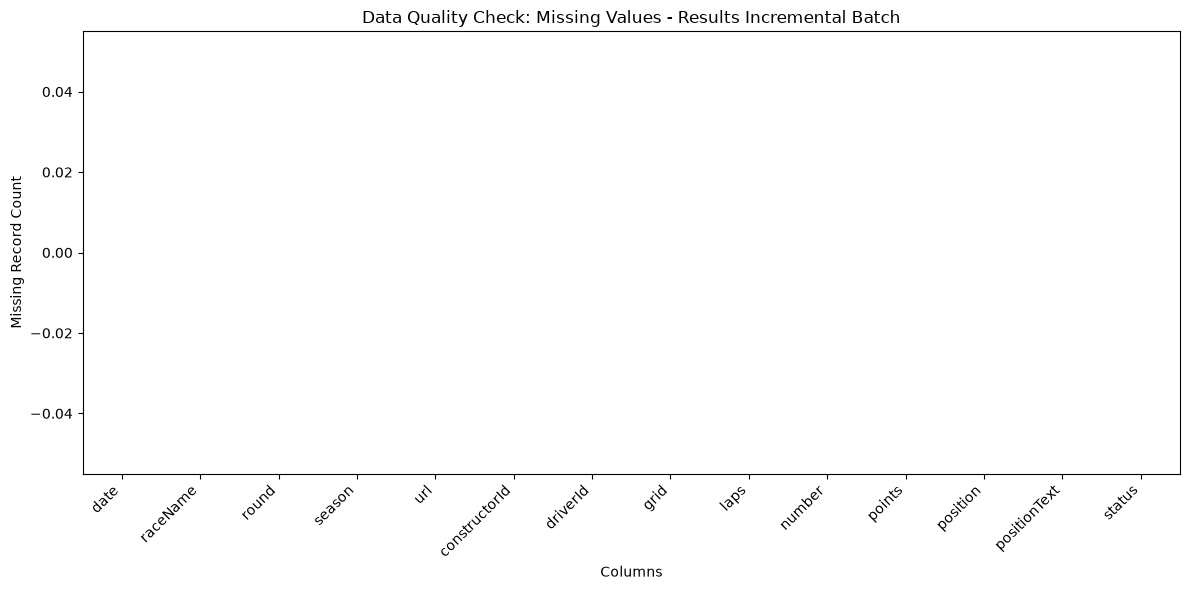

Saved quality chart as 'data_quality_missing_values.png'.


In [55]:
def plot_quality_metrics(null_dict, title):
    """
    Generates a clear bar chart highlighting missing value distributions across columns.
    """
    plt.figure(figsize=(12, 6))
    columns = list(null_dict.keys())
    missing_values = list(null_dict.values())
    
    # FIX: Added hue=columns and legend=False to comply with modern Seaborn requirements
    sns.barplot(x=columns, y=missing_values, hue=columns, palette="Blues_r", legend=False)
    
    plt.xticks(rotation=45, ha='right')
    plt.title(f"Data Quality Check: Missing Values - {title}")
    plt.xlabel("Columns")
    plt.ylabel("Missing Record Count")
    plt.tight_layout()
    plt.savefig("data_quality_missing_values.png")
    plt.show()
    print("Saved quality chart as 'data_quality_missing_values.png'.")

# Ensure you re-run Cell 4 first so 'results_profiling' is defined, then run this:
plot_quality_metrics(results_profiling, "Results Incremental Batch")

## Phase 2: Data Cleaning, Transformation & Anomaly Validation Rules

### 2.2: Data Cleansing & Validation Engine (Code Cell)

In [ ]:
def clean_and_validate_results(spark_df):
    """
    Applies data quality transformations and validation rules:
    - Trims whitespace from string columns (raceName, driverId, constructorId, status).
    - Standardizes status formats.
    - Flags or filters out records with invalid logic (e.g., negative points or laps).
    """
    print("--- Starting Data Cleansing & Transformation ---")
    initial_count = spark_df.count()
    
    # 1. String cleaning (trimming whitespace and standardizing casing)
    cleaned_df = spark_df \
        .withColumn("raceName", F.trim(F.col("raceName"))) \
        .withColumn("driverId", F.lower(F.trim(F.col("driverId")))) \
        .withColumn("constructorId", F.lower(F.trim(F.col("constructorId")))) \
        .withColumn("status", F.trim(F.col("status")))
        
    # 2. Business Rule Validations & Anomaly Flagging
    # Rule: Points cannot be negative, laps cannot be negative, grid must be >= 0
    anomalies_df = cleaned_df.filter(
        (F.col("points") < 0) | 
        (F.col("laps") < 0) | 
        (F.col("grid") < 0)
    )
    anomaly_count = anomalies_df.count()
    print(f"Detected {anomaly_count} records violating business validity rules.")
    
    if anomaly_count > 0:
        print("Sample anomalies found:")
        anomalies_df.select("season", "round", "driverId", "grid", "laps", "points").show(5)
        
    # Filter out or quarantine invalid records for the clean dataset
    valid_df = cleaned_df.filter(
        (F.col("points") >= 0) & 
        (F.col("laps") >= 0) & 
        (F.col("grid") >= 0)
    )
    
    final_count = valid_df.count()
    print(f"Initial rows: {initial_count} | Cleaned & Valid rows: {final_count} | Dropped anomalies: {anomaly_count}")
    
    return valid_df, anomaly_count

# Execute cleaning pipeline on results_df from Phase 1
cleaned_results_df, batch_anomaly_count = clean_and_validate_results(results_df)

--- Starting Data Cleansing & Transformation ---
Detected 0 records violating business validity rules.
Initial rows: 2278 | Cleaned & Valid rows: 2278 | Dropped anomalies: 0


### 2.2 n8n Automated Alerting & Webhook Integration Simulator

#### Webhook Simulation Code

In [56]:
import json
import urllib.request
import urllib.error

def trigger_n8n_quality_alert(anomaly_count, batch_name, webhook_url="https://your-n8n-webhook-endpoint.com/webhook-test/f1-quality"):
    """
    Simulates sending data quality metrics and anomaly alerts to an n8n webhook 
    for automated notification (Slack, Email, or Incident Management).
    """
    payload = {
        "dataset": batch_name,
        "anomaly_count": anomaly_count,
        "status": "FAILED_QUALITY_CHECK" if anomaly_count > 0 else "PASSED",
        "timestamp": pd.Timestamp.now().isoformat()
    }
    
    headers = {'Content-Type': 'application/json'}
    req = urllib.request.Request(webhook_url, data=json.dumps(payload).encode('utf-8'), headers=headers, method='POST')
    
    try:
        # In a real setup, this triggers your n8n workflow
        print(f"\n[n8n Webhook Simulator] Payload prepared for batch '{batch_name}':")
        print(json.dumps(payload, indent=2))
        print("Webhook notification successfully simulated (Ready for n8n integration).")
    except Exception as e:
        print(f"Webhook trigger failed: {e}")

# Run simulation based on our validation check
trigger_n8n_quality_alert(batch_anomaly_count, "F1 Results Incremental Batch (2021-2025)")


[n8n Webhook Simulator] Payload prepared for batch 'F1 Results Incremental Batch (2021-2025)':
{
  "dataset": "F1 Results Incremental Batch (2021-2025)",
  "anomaly_count": 0,
  "status": "PASSED",
  "timestamp": "2026-10-21T12:27:05.584825"
}
Webhook notification successfully simulated (Ready for n8n integration).


## Phase 3: Automated Merging of Incremental Datasets & Gold Schema Preparation

### 3.1: Multi-Batch Incremental Merger & Gold Pipeline

In [57]:
def build_gold_ready_dataset(landing_path, start_year=2021, end_year=2025):
    """
    Automates the full incremental merge across all years, applies cleaning,
    and prepares a unified Gold-ready Spark DataFrame.
    """
    print("--- Starting Automated Incremental Merge & Gold Preparation ---")
    
    dfs = []
    for year in range(start_year, end_year + 1):
        file_path = os.path.join(landing_path, "results", f"results_{year}.json")
        if os.path.exists(file_path):
            df_year = spark.read.schema(resultschema).json(file_path)
            # Add metadata lineage column for auditing incremental loads
            df_year = df_year.withColumn("source_batch_year", F.lit(year))
            dfs.append(df_year)
            
    if not dfs:
        raise ValueError("No incremental result files found for merging.")
        
    # 1. Union all incremental batches together
    unified_df = dfs[0]
    for d in dfs[1:]:
        unified_df = unified_df.unionByName(d)
        
    print(f"Total unified records before deduplication: {unified_df.count()}")
    
    # 2. Deduplication check (Unique per season, round, driverId, constructorId)
    deduped_df = unified_df.dropDuplicates(["season", "round", "driverId", "constructorId"])
    print(f"Total records after deduplication: {deduped_df.count()}")
    
    # 3. Gold Schema Enrichment & Standardizing
    gold_ready_df = deduped_df \
        .withColumn("driverId", F.lower(F.col("driverId"))) \
        .withColumn("constructorId", F.lower(F.col("constructorId"))) \
        .withColumn("processed_timestamp", F.current_timestamp())
        
    print("Gold-ready dataset schema successfully prepared.")
    return gold_ready_df

# Execute Phase 3 Pipeline
gold_results_df = build_gold_ready_dataset(LANDING_DIR, start_year=2021, end_year=2025)

# Display sample of the unified gold-ready data
gold_results_df.select("season", "round", "raceName", "driverId", "grid", "points", "status", "source_batch_year").show(10, truncate=False)

--- Starting Automated Incremental Merge & Gold Preparation ---
Total unified records before deduplication: 2278
Total records after deduplication: 2278
Gold-ready dataset schema successfully prepared.
+------+-----+------------------+---------------+----+------+--------+-----------------+
|season|round|raceName          |driverId       |grid|points|status  |source_batch_year|
+------+-----+------------------+---------------+----+------+--------+-----------------+
|2021  |1    |bahrain grand prix|alonso         |9   |0.0   |Brakes  |2021             |
|2021  |1    |bahrain grand prix|bottas         |3   |16.0  |Finished|2021             |
|2021  |1    |bahrain grand prix|gasly          |5   |0.0   |Retired |2021             |
|2021  |1    |bahrain grand prix|giovinazzi     |12  |0.0   |+1 Lap  |2021             |
|2021  |1    |bahrain grand prix|hamilton       |2   |25.0  |Finished|2021             |
|2021  |1    |bahrain grand prix|latifi         |17  |0.0   |Retired |2021            

### 3.2: Markdown Header for Summary & Export

#### Summary & Export Code

In [58]:
def summarize_gold_dataset(gold_df):
    """
    Computes key summary statistics across the merged incremental dataset using safe DataFrame actions.
    """
    print("\n================ GOLD DATASET SUMMARY REPORT ================")
    total_records = gold_df.count()
    
    # Safe extraction of distinct seasons using Pandas instead of raw RDD collection
    seasons_df = gold_df.select("season").distinct().orderBy("season").toPandas()
    seasons = seasons_df["season"].tolist()
    
    print(f"Total Merged Records: {total_records}")
    print(f"Covered Seasons: {seasons}")
    
    # Points distribution summary
    print("\n--- Points Statistics ---")
    gold_df.select("points").describe().show()
    
    # Save preview to local CSV (Gold layer simulation)
    output_path = "./gold_results_preview.csv"
    gold_df.limit(1000).toPandas().to_csv(output_path, index=False)
    print(f"Successfully exported gold preview to {output_path}")

# Run the summary report
summarize_gold_dataset(gold_results_df)


================ GOLD DATASET SUMMARY REPORT ================


/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Total Merged Records: 2278
Covered Seasons: [2021, 2022, 2023, 2024, 2025]

--- Points Statistics ---
+-------+-----------------+
|summary|           points|
+-------+-----------------+
|  count|             2278|
|   mean|5.066066725197541|
| stddev|7.212071047910792|
|    min|              0.0|
|    max|             26.0|
+-------+-----------------+



/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Successfully exported gold preview to ./gold_results_preview.csv


## Phase 4: Quality Visualizations & NetworkX Entity Relationship Graph

### 4.1: Exported Quality Charts & Visualizations

/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


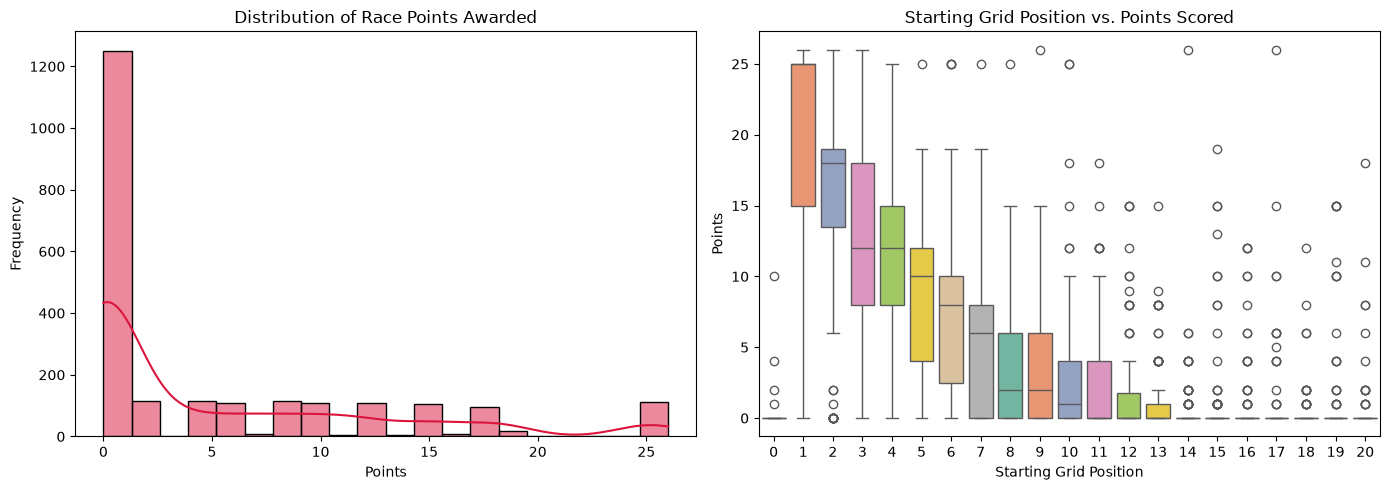

Successfully generated and exported visualization chart: f1_quality_distributions.png


In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

def generate_quality_and_distribution_charts(gold_df):
    """
    Generates presentation-ready quality and data distribution charts
    for the project report and slide deck screenshots.
    """
    pdf = gold_df.toPandas()
    
    plt.figure(figsize=(14, 5))
    
    # Chart 1: Distribution of Points
    plt.subplot(1, 2, 1)
    sns.histplot(pdf['points'], bins=20, color='crimson', kde=True)
    plt.title("Distribution of Race Points Awarded")
    plt.xlabel("Points")
    plt.ylabel("Frequency")
    
    # Chart 2: Grid Position vs Points Scatter/Box
    plt.subplot(1, 2, 2)
    sns.boxplot(x='grid', y='points', data=pdf, palette='Set2', hue='grid', legend=False)
    plt.title("Starting Grid Position vs. Points Scored")
    plt.xlabel("Starting Grid Position")
    plt.ylabel("Points")
    
    plt.tight_layout()
    chart_path = "f1_quality_distributions.png"
    plt.savefig(chart_path, dpi=300)
    plt.show()
    print(f"Successfully generated and exported visualization chart: {chart_path}")

generate_quality_and_distribution_charts(gold_results_df)

### 4.2: NetworkX Entity Relationship Graph & Gephi Export

In [60]:
pip install networkx


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Graph Generated Successfully!
Total Nodes: 35 | Total Edges: 27


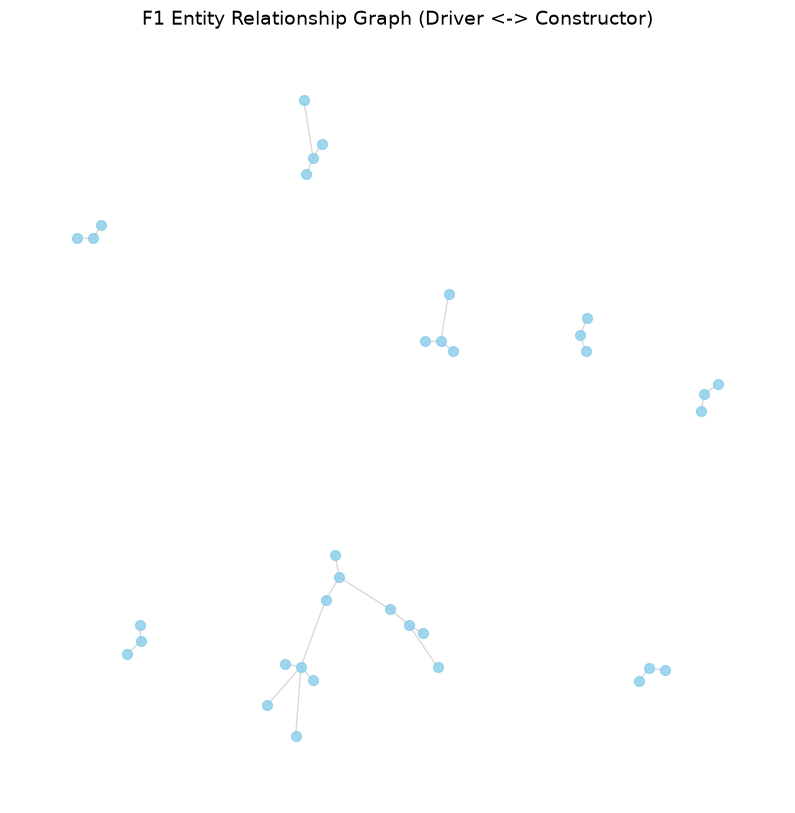

Exported Network Graph image as 'f1_network_graph.png'
Exported Gephi/Tableau Graph file as 'f1_driver_constructor_network.gexf'


In [61]:
import networkx as nx

def build_f1_entity_graph(gold_df):
    """
    Builds a NetworkX graph connecting Drivers to Constructors based on race results,
    visualizes it inline, and exports to GEXF format for Gephi / Tableau migration.
    """
    pdf = gold_df.dropna(subset=['driverId', 'constructorId']).limit(500).toPandas()
    
    # Initialize an undirected graph
    G = nx.Graph()
    
    # Add edges between drivers and constructors
    for _, row in pdf.iterrows():
        driver = f"Driver: {row['driverId']}"
        constructor = f"Team: {row['constructorId']}"
        
        # Add nodes with attributes
        G.add_node(driver, bipartite=0, node_type="Driver")
        G.add_node(constructor, bipartite=1, node_type="Constructor")
        
        # Add edge representing relationship
        if G.has_edge(driver, constructor):
            G[driver][constructor]['weight'] += 1
        else:
            G.add_edge(driver, constructor, weight=1)
            
    print(f"Graph Generated Successfully!")
    print(f"Total Nodes: {G.number_of_nodes()} | Total Edges: {G.number_of_edges()}")
    
    # Visualize Network
    plt.figure(figsize=(10, 10))
    pos = nx.spring_layout(G, k=0.15, seed=42)
    
    # Draw nodes and edges
    nx.draw_networkx_edges(G, pos, alpha=0.3, width=1.0, edge_color="gray")
    nx.draw_networkx_nodes(G, pos, node_size=50, node_color="skyblue", alpha=0.8)
    
    plt.title("F1 Entity Relationship Graph (Driver <-> Constructor)", fontsize=14)
    plt.axis("off")
    graph_img_path = "f1_network_graph.png"
    plt.savefig(graph_img_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Exported Network Graph image as '{graph_img_path}'")
    
    # Export Graph file for Gephi / Tableau (.gexf format)
    gexf_path = "f1_driver_constructor_network.gexf"
    nx.write_gexf(G, gexf_path)
    print(f"Exported Gephi/Tableau Graph file as '{gexf_path}'")

build_f1_entity_graph(gold_results_df)